# ML-Based Phishing Email Detector

## Goal

Train a supervised machine-learning model that predicts whether an email
is phishing/spam or legitimate.

The model will output:

    P(phishing) ∈ [0, 1]

This model will later be loaded by the main LangGraph notebook as one of
the independent signals in the final phishing-risk calculation.

## Initial Model

TF-IDF
   ↓
Logistic Regression
   ↓
Phishing probability

## Dataset

Phishing Email Dataset by Naser Abdullah Alam.

Main file:
    phishing_email.csv

Main fields:
    text_combined
    label

Label convention:
    0 = legitimate
    1 = phishing/spam

## Important

This notebook intentionally starts with a simple, strong baseline.

Later experiments should explore alternatives such as:

- Character + word TF-IDF
- Linear SVM
- Naive Bayes
- XGBoost with engineered email/security features
- Hybrid text + structural models
- Transformer-based classifiers

The deployed model for Notebook 2 will remain behind a common
`predict_proba()` interface regardless of which model eventually wins.

## Environment

Run with the **Python (agentic-phishing)** kernel from the project
root (same venv as `agentic_phishing.ipynb`). Dependencies are installed
from `requirements.txt`:

```powershell
.venv\Scripts\python.exe -m pip install -r requirements.txt
```

The dataset is fetched with `kagglehub`, which caches it under the user
home directory, so reruns do not re-download. This notebook overwrites
`phishing_detector.joblib` and `model_metadata.json` in the project
root, which is where `agentic_phishing.ipynb` loads them from.

In [1]:
import os
import re
import json
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Environment ready.")
print("Random seed:", SEED)

Environment ready.
Random seed: 42


In [2]:
import kagglehub

DATASET_ID = "naserabdullahalam/phishing-email-dataset"

print(f"Downloading: {DATASET_ID}")

dataset_path = kagglehub.dataset_download(
    DATASET_ID
)

print("\nDataset downloaded to:")
print(dataset_path)

C:\Users\91626\OneDrive - Manipal Academy of Higher Education\Desktop\projects\agentic-phishing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Downloading: naserabdullahalam/phishing-email-dataset



Dataset downloaded to:
C:\Users\91626\.cache\kagglehub\datasets\naserabdullahalam\phishing-email-dataset\versions\1


In [3]:
# Dataset version selector.
#   v1_alam      - normalized phishing_email.csv (lowercased, punctuation stripped)
#   v2_email4s   - HF Email4S raw text (~18.6k emails)
#   v3_per_source- per-source CSVs with raw text + subjects (~82k emails)
DATASET_VERSION = "v3_per_source"

# v1 runs may replace the deployed artifact directly. Other dataset versions
# must beat the incumbent artifact's test ROC-AUC (see the deploy cell).
DEPLOY_OVERRIDE = DATASET_VERSION == "v1_alam"

print("DATASET_VERSION:", DATASET_VERSION)
print("DEPLOY_OVERRIDE:", DEPLOY_OVERRIDE)

DATASET_VERSION: v3_per_source
DEPLOY_OVERRIDE: False


In [4]:
PER_SOURCE_FILES = [
    "CEAS_08.csv",
    "Enron.csv",
    "Ling.csv",
    "Nazario.csv",
    "Nigerian_Fraud.csv",
    "SpamAssasin.csv",
]

if DATASET_VERSION == "v2_email4s":
    from huggingface_hub import hf_hub_download

    CSV_PATH = Path(hf_hub_download(
        repo_id="zefang-liu/phishing-email-dataset",
        filename="Phishing_Email.csv",
        repo_type="dataset",
    ))

    raw = pd.read_csv(CSV_PATH)

    raw = raw.rename(
        columns={
            "Email Text": "text_combined",
            "Email Type": "label",
        }
    )

    raw["label"] = raw["label"].map({
        "Safe Email": 0,
        "Phishing Email": 1,
    })

    df = raw[["text_combined", "label"]].copy()

    df["text_combined"] = (
        df["text_combined"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    df = df[df["text_combined"].str.len() > 0]

    df = df[
        ~df["text_combined"]
        .str.lower()
        .isin(["null", "empty", "nan"])
    ]
elif DATASET_VERSION == "v3_per_source":
    dataset_path = Path(dataset_path)

    frames = []

    for name in PER_SOURCE_FILES:
        part = pd.read_csv(dataset_path / name)

        part = part.dropna(subset=["label"])

        subject = part["subject"].fillna("").astype(str).str.strip()
        body = part["body"].fillna("").astype(str).str.strip()

        text = (subject + "\n" + body).str.strip()

        frames.append(
            pd.concat(
                [
                    text.rename("text_combined"),
                    part["label"].astype(int).rename("label"),
                ],
                axis=1,
            )
        )

    df = pd.concat(frames, ignore_index=True)

    df = df[df["text_combined"].str.len() > 0]

    CSV_PATH = f"{len(PER_SOURCE_FILES)} per-source CSVs"
else:
    dataset_path = Path(dataset_path)

    csv_candidates = list(
        dataset_path.rglob("phishing_email.csv")
    )

    if not csv_candidates:
        all_csvs = list(dataset_path.rglob("*.csv"))

        print("Could not find phishing_email.csv.")
        print("\nCSV files found:")

        for path in all_csvs:
            print(" -", path)

        raise FileNotFoundError(
            "phishing_email.csv was not found."
        )

    CSV_PATH = csv_candidates[0]

    df = pd.read_csv(
        CSV_PATH,
        low_memory=False
    )

print("Loaded:", CSV_PATH)
print("Shape:", df.shape)

Loaded: 6 per-source CSVs
Shape: (82486, 2)


In [5]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (82486, 2)

Columns:
['text_combined', 'label']


,text_combined,label
0,"Never agree to be a loser\nBuck up, your troub...",1
1,Befriend Jenna Jameson\nUpgrade your sex and p...,1
2,CNN.com Daily Top 10\n>+=+=+=+=+=+=+=+=+=+=+=+...,1
3,Re: svn commit: r619753 - in /spamassassin/tru...,0
4,SpecialPricesPharmMoreinfo\nWelcomeFastShippin...,1


In [6]:
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(
    df.isna().sum().sort_values(
        ascending=False
    ).to_frame("missing")
)

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (82486, 2)

Data types:
text_combined      str
label            int64
dtype: object

Missing values:


,missing
text_combined,0
label,0



Duplicate rows: 95


In [7]:
required_columns = {
    "text_combined",
    "label",
}

missing_columns = (
    required_columns
    - set(df.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required columns found.")

Required columns found.


In [8]:
print("Label distribution:")

label_counts = (
    df["label"]
    .value_counts()
    .sort_index()
)

display(
    label_counts.to_frame("count")
)

print("\nPercentages:")

display(
    (
        df["label"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
        .to_frame("percentage")
    )
)

Label distribution:


,count
label,
0,39595
1,42891



Percentages:


,percentage
label,
0,48.0
1,52.0


In [9]:
df = df[
    [
        "text_combined",
        "label",
    ]
].copy()

df.rename(
    columns={
        "text_combined": "text",
        "label": "target",
    },
    inplace=True,
)

print(df.shape)
display(df.head())

(82486, 2)


,text,target
0,"Never agree to be a loser\nBuck up, your troub...",1
1,Befriend Jenna Jameson\nUpgrade your sex and p...,1
2,CNN.com Daily Top 10\n>+=+=+=+=+=+=+=+=+=+=+=+...,1
3,Re: svn commit: r619753 - in /spamassassin/tru...,0
4,SpecialPricesPharmMoreinfo\nWelcomeFastShippin...,1


In [10]:
# Convert labels to integers.
df["target"] = pd.to_numeric(
    df["target"],
    errors="coerce"
)

# Convert text safely to strings.
df["text"] = df["text"].fillna("").astype(str)

# Remove completely empty emails.
df["text"] = df["text"].str.strip()

before = len(df)

df = df[
    df["text"].str.len() > 0
].copy()

after = len(df)

print(
    f"Removed {before - after:,} empty records."
)

print(
    "\nFinal label values:",
    sorted(df["target"].unique())
)

Removed 0 empty records.

Final label values: [np.int64(0), np.int64(1)]


In [11]:
before = len(df)

df = df.drop_duplicates(
    subset=["text", "target"]
).reset_index(drop=True)

after = len(df)

print(
    f"Removed {before - after:,} exact duplicate emails."
)

print(
    f"Remaining records: {len(df):,}"
)

Removed 95 exact duplicate emails.
Remaining records: 82,391


In [12]:
invalid_labels = ~df["target"].isin([0, 1])

if invalid_labels.any():
    print(
        "Invalid labels found:",
        invalid_labels.sum()
    )

    display(
        df.loc[
            invalid_labels,
            ["target"]
        ].value_counts()
    )

    raise ValueError(
        "Dataset contains labels other than 0 and 1."
    )

print("Binary labels confirmed: 0 / 1")

Binary labels confirmed: 0 / 1


In [13]:
df["text_length"] = df["text"].str.len()
df["word_count"] = (
    df["text"]
    .str.split()
    .str.len()
)

display(
    df.groupby("target")[
        ["text_length", "word_count"]
    ].describe().round(2)
)

text_length                                                             \
             count     mean       std   min    25%     50%     75%        max   
target                                                                          
0          39588.0  2198.83   5386.86  16.0  566.0  1116.0  2177.0   299272.0   
1          42803.0  1424.28  22929.25   3.0  244.0   501.0  1503.0  4599694.0   

       word_count                                                      
            count    mean     std  min    25%    50%    75%       max  
target                                                                 
0         39588.0  363.52  862.27  2.0  95.75  190.0  377.0   45450.0  
1         42803.0  201.61  743.73  1.0  40.00   89.0  263.0  127127.0

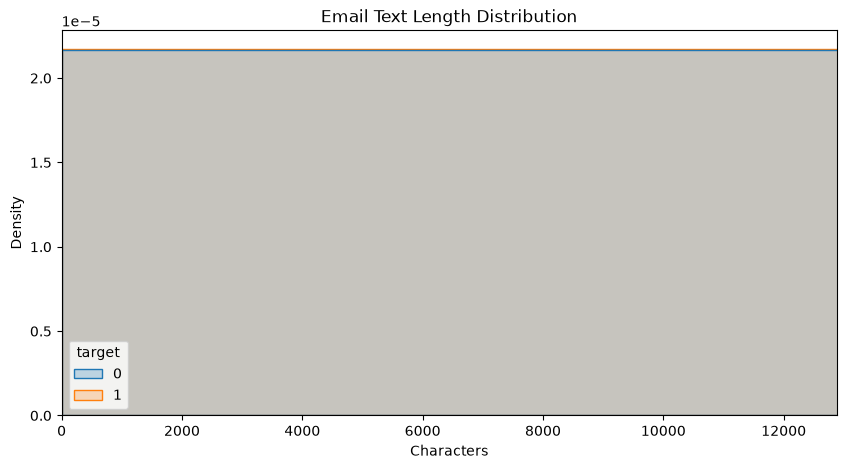

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="text_length",
    hue="target",
    bins=100,
    element="step",
    stat="density",
    common_norm=False,
)

plt.xlim(
    0,
    df["text_length"].quantile(0.99)
)

plt.title("Email Text Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Density")
plt.show()

## EDA: structural feature correlations

Engineered structural features (lengths, ratios, link and punctuation
counts) and their correlation with the phishing label. Correlations here
are computed on the full cleaned dataset and are purely descriptive.

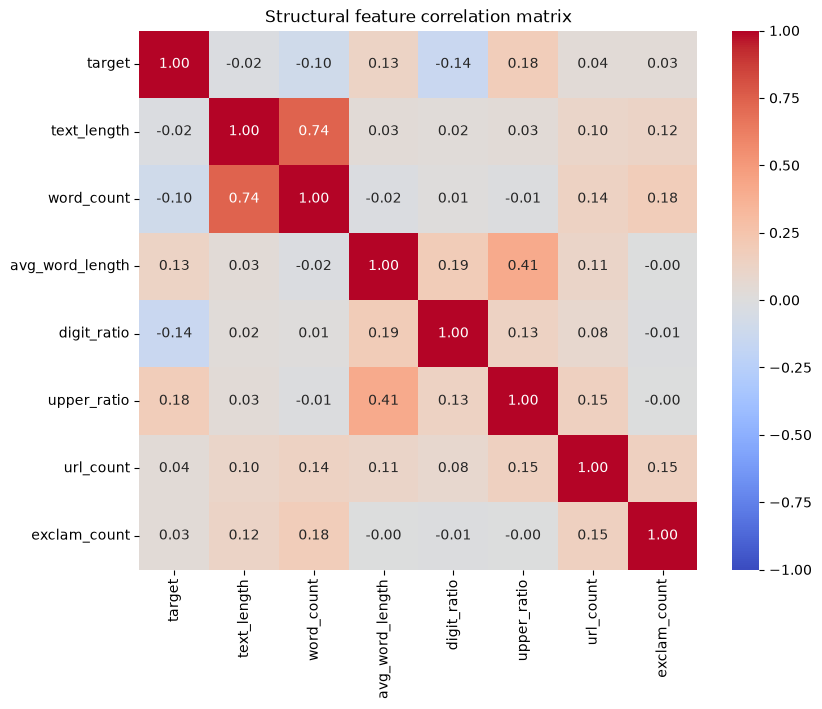

,correlation_with_target
digit_ratio,-0.142230
word_count,-0.100247
text_length,-0.022834
exclam_count,0.034171
url_count,0.035582
avg_word_length,0.125336
upper_ratio,0.181286


In [15]:
# EDA: structural features vs target correlation heatmap.
eda_df = df[["target"]].copy()

text = df["text"]

eda_df["text_length"] = text.str.len()
eda_df["word_count"] = text.str.split().str.len()
eda_df["avg_word_length"] = (
    eda_df["text_length"]
    / eda_df["word_count"].clip(lower=1)
)
eda_df["digit_ratio"] = (
    text.str.count(r"\d")
    / eda_df["text_length"]
)
eda_df["upper_ratio"] = (
    text.str.count(r"[A-Z]")
    / eda_df["text_length"]
)
eda_df["url_count"] = text.str.count(r"http|www")
eda_df["exclam_count"] = text.str.count("!")

correlations = eda_df.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Structural feature correlation matrix")
plt.show()

display(
    correlations["target"]
    .drop("target")
    .sort_values()
    .to_frame("correlation_with_target")
)

In [16]:
model_df = df[
    ["text", "target"]
].copy()

print("Modeling dataset:")
print(model_df.shape)

print("\nClass counts:")
print(
    model_df["target"]
    .value_counts()
    .sort_index()
)

Modeling dataset:
(82391, 2)

Class counts:
target
0    39588
1    42803
Name: count, dtype: int64


In [17]:
X = model_df["text"]
y = model_df["target"]

# First:
# 70% train
# 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

# Then divide temporary set equally:
# 15% validation
# 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print(
    f"Train:      {len(X_train):,}"
)

print(
    f"Validation: {len(X_val):,}"
)

print(
    f"Test:       {len(X_test):,}"
)

print("\nClass proportions:")

print(
    "\nTrain:\n",
    y_train.value_counts(normalize=True)
)

print(
    "\nValidation:\n",
    y_val.value_counts(normalize=True)
)

print(
    "\nTest:\n",
    y_test.value_counts(normalize=True)
)

Train:      57,673
Validation: 12,359
Test:       12,359

Class proportions:

Train:
 target
1    0.519515
0    0.480485
Name: proportion, dtype: float64

Validation:
 target
1    0.51946
0    0.48054
Name: proportion, dtype: float64

Test:
 target
1    0.51954
0    0.48046
Name: proportion, dtype: float64


In [18]:
# Initial baseline:
#
# TF-IDF → Logistic Regression
#
# This is intentionally simple.
#
# FUTURE EXPERIMENTS:
# - word + character TF-IDF
# - LinearSVC
# - Naive Bayes
# - XGBoost with engineered email/security features
# - hybrid text + structural model
# - transformer-based classifier
#
# We should only replace this baseline after measuring
# whether another architecture materially improves performance.

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        )
    ),

    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        )
    ),
])

print(model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=50000, min_df=2,
                                 ngram_range=(1, 2), strip_accents='unicode',
                                 sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42,
                                    solver='liblinear'))])


In [19]:
print("Training TF-IDF + Logistic Regression...")

model.fit(
    X_train,
    y_train
)

print("Training complete.")

Training TF-IDF + Logistic Regression...


Training complete.


In [20]:
val_pred = model.predict(
    X_val
)

val_prob = model.predict_proba(
    X_val
)[:, 1]

print(
    "Validation predictions generated."
)

Validation predictions generated.


In [21]:
def evaluate_classifier(
    y_true,
    y_pred,
    y_prob,
    split_name="Dataset"
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            y_prob
        ),

        "pr_auc": average_precision_score(
            y_true,
            y_prob
        ),
    }

    print(
        f"\n{split_name} Results"
    )
    print("=" * 40)

    for metric, value in metrics.items():
        print(
            f"{metric:12s}: {value:.4f}"
        )

    return metrics

In [22]:
val_metrics = evaluate_classifier(
    y_val,
    val_pred,
    val_prob,
    split_name="Validation"
)


Validation Results
accuracy    : 0.9884
precision   : 0.9874
recall      : 0.9903
f1          : 0.9889
roc_auc     : 0.9993
pr_auc      : 0.9994


In [23]:
print(
    classification_report(
        y_val,
        val_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9895    0.9864    0.9879      5939
    Phishing     0.9874    0.9903    0.9889      6420

    accuracy                         0.9884     12359
   macro avg     0.9885    0.9884    0.9884     12359
weighted avg     0.9884    0.9884    0.9884     12359



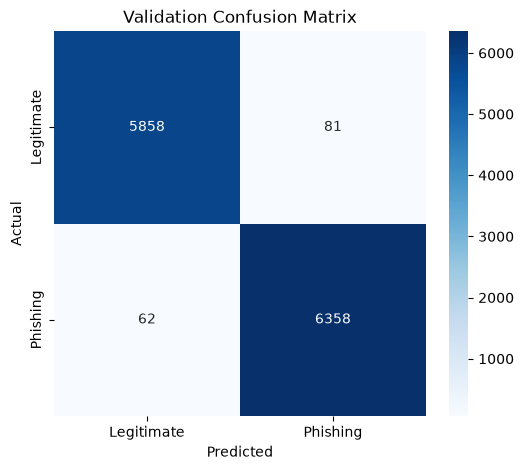

In [24]:
cm = confusion_matrix(
    y_val,
    val_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Legitimate",
        "Phishing"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing"
    ],
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [25]:
thresholds = np.arange(
    0.10,
    0.96,
    0.05
)

threshold_results = []

for threshold in thresholds:

    pred = (
        val_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val,
            pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_val,
            pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_val,
            pred,
            zero_division=0
        ),
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.round(4)
)

,threshold,precision,recall,f1
0,0.10,0.8740,0.9997,0.9326
1,0.15,0.9142,0.9995,0.9550
2,0.20,0.9377,0.9989,0.9673
3,0.25,0.9529,0.9984,0.9751
4,0.30,0.9649,0.9977,0.9810
5,0.35,0.9720,0.9961,0.9839
6,0.40,0.9782,0.9936,0.9859
7,0.45,0.9841,0.9922,0.9881
8,0.50,0.9874,0.9903,0.9889
9,0.55,0.9898,0.9872,0.9885


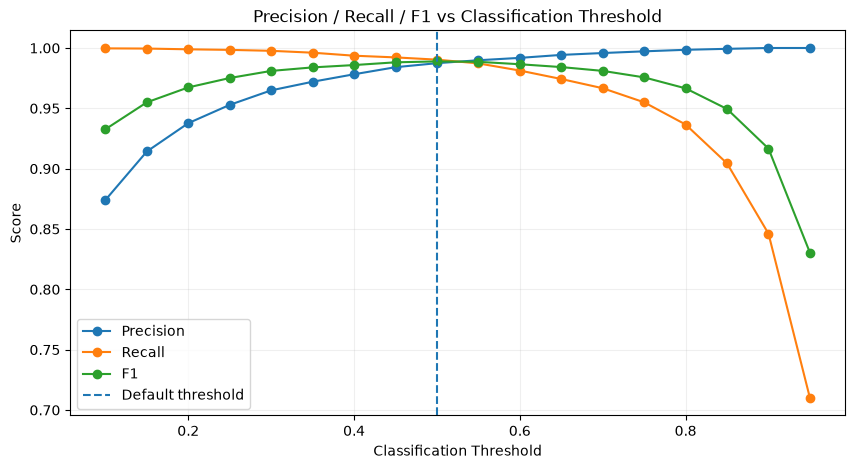

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Default threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title(
    "Precision / Recall / F1 vs Classification Threshold"
)

plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [27]:
test_pred = model.predict(
    X_test
)

test_prob = model.predict_proba(
    X_test
)[:, 1]

test_metrics = evaluate_classifier(
    y_test,
    test_pred,
    test_prob,
    split_name="Test"
)


Test Results
accuracy    : 0.9896
precision   : 0.9896
recall      : 0.9905
f1          : 0.9900
roc_auc     : 0.9994
pr_auc      : 0.9994


In [28]:
print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ],
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9897    0.9887    0.9892      5938
    Phishing     0.9896    0.9905    0.9900      6421

    accuracy                         0.9896     12359
   macro avg     0.9896    0.9896    0.9896     12359
weighted avg     0.9896    0.9896    0.9896     12359



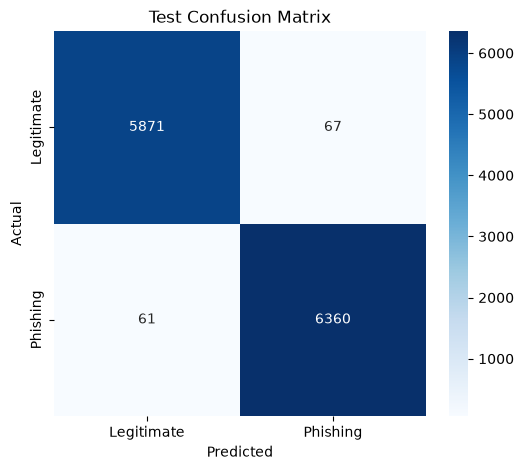

In [29]:
cm_test = confusion_matrix(
    y_test,
    test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Legitimate",
        "Phishing"
    ],
    yticklabels=[
        "Legitimate",
        "Phishing"
    ],
)

plt.title("Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

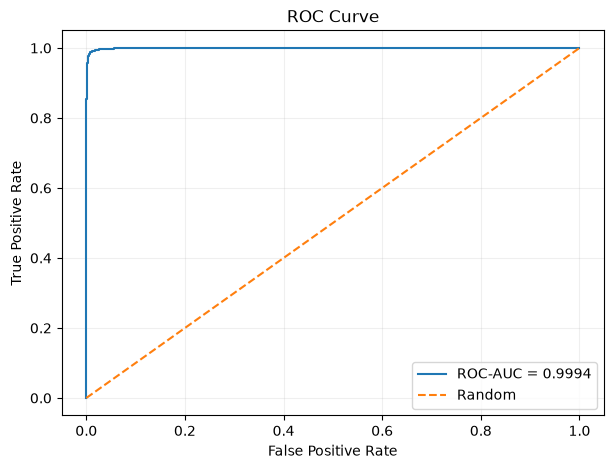

In [30]:
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
)

fpr, tpr, _ = roc_curve(
    y_test,
    test_prob
)

precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_test,
        test_prob
    )
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {test_metrics['roc_auc']:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

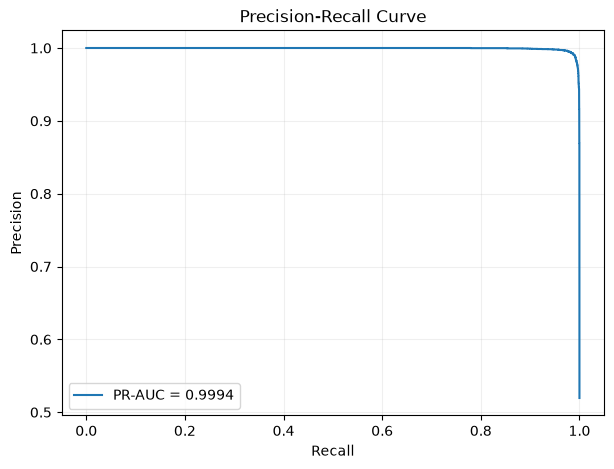

In [31]:
plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"PR-AUC = {test_metrics['pr_auc']:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [32]:
vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

feature_names = np.array(
    vectorizer.get_feature_names_out()
)

coefficients = classifier.coef_[0]

top_phishing_idx = np.argsort(
    coefficients
)[-30:][::-1]

top_legitimate_idx = np.argsort(
    coefficients
)[:30]

print("Top phishing-associated features:")
print(
    feature_names[
        top_phishing_idx
    ]
)

print("\nTop legitimate-associated features:")
print(
    feature_names[
        top_legitimate_idx
    ]
)

Top phishing-associated features:
['your' 'you' 'our' 'love' 'here' 'com' 'life' '2004' 'http' 'men'
 'account' 'money' 'her' 'remove' 'watches' '2005' 'man' 'monkey org'
 'site' 'watch' 'quality' 'replica' 'monkey' 'sex' 'bank' 'health'
 'click here' 'jose' 'no' 'jose monkey']

Top legitimate-associated features:
['enron' 'wrote' 'the' 'thanks' 'vince' 'on' 'louise' '2008' 'opensuse'
 'university' 'org' '2007' '2000' 'to' '2001' '713' 'that' 'edu'
 'attached' 'doc' 'date' 'at' 'url http' 'python' '2002' 'perl' 'fork'
 'would' 'language' 'pm']


In [33]:
analysis_df = pd.DataFrame({
    "text": X_test.values,
    "actual": y_test.values,
    "predicted": test_pred,
    "probability": test_prob,
})

false_positives = analysis_df[
    (analysis_df["actual"] == 0)
    & (analysis_df["predicted"] == 1)
].sort_values(
    "probability",
    ascending=False
)

false_negatives = analysis_df[
    (analysis_df["actual"] == 1)
    & (analysis_df["predicted"] == 0)
].sort_values(
    "probability",
    ascending=True
)

print(
    "False positives:",
    len(false_positives)
)

print(
    "False negatives:",
    len(false_negatives)
)

False positives: 67
False negatives: 61


In [34]:
print("=" * 80)
print("FALSE POSITIVES")
print("=" * 80)

for i, row in false_positives.head(5).iterrows():

    print(
        f"\nProbability: "
        f"{row['probability']:.4f}"
    )

    print(
        row["text"][:2000]
    )

    print("-" * 80)

FALSE POSITIVES

Probability: 0.9361
CNN Alerts: bush
CNN Alerts: bush






 



Alert Name: bush
Nation's bridges, roads still 'structurally deficient'

08/01/08 11:55 AM, EDT
Mercedes Gorden remembers August 1, 2007, like it was yesterday.
FULL STORY



You have agreed to receive this email from CNN.com as a result of your CNN.com preference settings.
To manage your settings click here.                               
To alter your alert criteria or frequency or to unsubscribe from receiving custom email alerts, click here.


Cable News Network. One CNN Center, Atlanta, Georgia 30303
© 2008 Cable News Network.
A Time Warner Company
All Rights Reserved.
View our privacy policy and terms.
--------------------------------------------------------------------------------

Probability: 0.9080
Memo, ignite a blaze of wealth on August 23rd.
I have something for you so wonderful and inspiring, that it will be 
like stepping into a dazzle of  sunlight, and all the possibilities of life 
will u

In [35]:
print("=" * 80)
print("FALSE NEGATIVES")
print("=" * 80)

for i, row in false_negatives.head(5).iterrows():

    print(
        f"\nProbability: "
        f"{row['probability']:.4f}"
    )

    print(
        row["text"][:2000]
    )

    print("-" * 80)

FALSE NEGATIVES

Probability: 0.0618
positions available : microsoft research - university of trento centre
* * * * * * * * * * apologize for multiple posting * * * * * * * * * * * * * *
the new interdisciplinary centre of excellence
microsoft research - university of trento centre for computational and systems biology
has been established in the trento region ( italy ) . the main objectives and activities of the centre are :
overall objectives
1 . to advance the state of knowledge of biological information processing , the aetiology of disease , and potentially new therapies through the creation of a new research centre that will bring together scientists from multiple disciplines to focus on conducting leading research into advanced computational modeling of biological systems .
2 . to conduct novel research into defining new computational and communication paradigms that are ' biomimetic ' in nature , i . e . , based on new principles learned from the research into biological inform

In [36]:
X_train_final = pd.concat(
    [
        X_train,
        X_val
    ],
    axis=0
)

y_train_final = pd.concat(
    [
        y_train,
        y_val
    ],
    axis=0
)

print(
    "Final training records:",
    len(X_train_final)
)

print(
    "Held-out test records:",
    len(X_test)
)

Final training records: 70032
Held-out test records: 12359


In [37]:
final_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        )
    ),

    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        )
    ),
])

print("Training final deployment model...")

final_model.fit(
    X_train_final,
    y_train_final
)

print("Final model trained.")

Training final deployment model...


Final model trained.


In [38]:
# Artifact paths. The export only happens when this run is allowed to
# replace the deployed artifact (see the ensemble deploy cell below).
ARTIFACT_DIR = Path.cwd()

if not (ARTIFACT_DIR / "README.md").is_file():
    raise RuntimeError(
        "phishing_ml.ipynb must be run from the project root "
        "(README.md not found in the current directory)."
    )

MODEL_ARTIFACT_PATH = (
    ARTIFACT_DIR
    / "phishing_detector.joblib"
)

if DEPLOY_OVERRIDE:
    joblib.dump(
        final_model,
        MODEL_ARTIFACT_PATH
    )

    print("Saved model to:")
    print(MODEL_ARTIFACT_PATH)

    print(
        f"\nSize: "
        f"{MODEL_ARTIFACT_PATH.stat().st_size / 1024**2:.2f} MB"
    )
else:
    print(
        "DEPLOY_OVERRIDE is False; "
        "baseline artifact NOT exported."
    )

DEPLOY_OVERRIDE is False; baseline artifact NOT exported.


In [39]:
metadata = {
    "model_name": "TF-IDF + Logistic Regression",
    "dataset_version": DATASET_VERSION,
    "dataset": {
        "name": "Phishing Email Dataset",
        "source": "Naser Abdullah Alam / Kaggle"
        if DATASET_VERSION == "v1_alam"
        else "Email4S / HF zefang-liu/phishing-email-dataset",
        "text_column": "text_combined",
        "label_column": "label",
        "label_mapping": {
            "0": "legitimate",
            "1": "phishing_spam",
        },
    },
    "preprocessing": {
        "lowercase": True,
        "strip_accents": "unicode",
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_features": 50000,
        "sublinear_tf": True,
    },
    "classifier": {
        "algorithm": "LogisticRegression",
        "C": 1.0,
        "solver": "liblinear",
        "max_iter": 1000,
    },
    "split": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15,
        "random_state": SEED,
    },
    "test_metrics": {
        key: float(value)
        for key, value in test_metrics.items()
    },
}

METADATA_PATH = (
    ARTIFACT_DIR
    / "model_metadata.json"
)

if DEPLOY_OVERRIDE:
    with open(
        METADATA_PATH,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            metadata,
            f,
            indent=2
        )

    print("Saved metadata to:")
    print(METADATA_PATH)
else:
    print(
        "DEPLOY_OVERRIDE is False; "
        "baseline metadata NOT exported."
    )

DEPLOY_OVERRIDE is False; baseline metadata NOT exported.


## Experiment 1: feature-diverse soft-voting ensemble

Three lightweight, CPU-friendly branches over different views of the text:

1. **word_lr** - word TF-IDF (1-2 grams) + LogisticRegression (the baseline)
2. **char_nb** - hashed char n-grams (3-4) + MultinomialNB
3. **char_svc** - hashed char n-grams (3-4) + calibrated LinearSVC

`HashingVectorizer` bounds memory usage: no vocabulary dictionary is ever
built, and float32 keeps the sparse matrices small. Voting is soft, so the
exported artifact keeps the `predict_proba([text])[0, 1]` contract.

In [40]:
from sklearn.ensemble import VotingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.feature_extraction.text import (
    HashingVectorizer,
    TfidfTransformer,
)
from sklearn.pipeline import FeatureUnion
from sklearn.preprocessing import (
    FunctionTransformer,
    MaxAbsScaler,
)
from scipy import sparse

def url_count_feature(raw_documents):
    """Sparse column of per-email URL counts.

    Object dtype avoids Numpy's fixed-width U-dtype, which would
    pad every email to the length of the longest outlier email.
    """
    if hasattr(raw_documents, "to_numpy"):
        docs = raw_documents.to_numpy(dtype=object)
    else:
        docs = np.asarray(raw_documents, dtype=object).ravel()

    counts = np.fromiter(
        (
            len(re.findall(r"https?://|www\.", doc.lower()))
            for doc in docs
        ),
        dtype=np.float32,
        count=len(docs),
    )
    return sparse.csr_matrix(counts.reshape(-1, 1))

def url_count_branch():
    return Pipeline([
        (
            "count",
            FunctionTransformer(url_count_feature),
        ),
        ("scale", MaxAbsScaler()),
    ])

def make_char_pipeline(classifier):
    return Pipeline([
        (
            "features",
            FeatureUnion([
                (
                    "char",
                    Pipeline([
                        (
                            "hash",
                            HashingVectorizer(
                                analyzer="char_wb",
                                ngram_range=(3, 4),
                                n_features=2**18,
                                alternate_sign=False,
                                norm=None,
                                dtype=np.float32,
                            ),
                        ),
                        ("tfidf", TfidfTransformer(sublinear_tf=True)),
                    ]),
                ),
                ("url", url_count_branch()),
            ]),
        ),
        ("classifier", classifier),
    ])

ensemble = VotingClassifier(
    estimators=[
        (
            "word_lr",
            Pipeline([
                (
                    "features",
                    FeatureUnion([
                        (
                            "word_tfidf",
                            TfidfVectorizer(
                                lowercase=True,
                                strip_accents="unicode",
                                ngram_range=(1, 2),
                                min_df=2,
                                max_features=50000,
                                sublinear_tf=True,
                            ),
                        ),
                        ("url", url_count_branch()),
                    ]),
                ),
                (
                    "classifier",
                    LogisticRegression(
                        C=1.0,
                        max_iter=1000,
                        solver="liblinear",
                        random_state=SEED,
                    ),
                ),
            ]),
        ),
        ("char_nb", make_char_pipeline(MultinomialNB())),
        (
            "char_svc",
            make_char_pipeline(
                CalibratedClassifierCV(
                    LinearSVC(C=1.0, dual="auto", random_state=SEED),
                    cv=3,
                    method="sigmoid",
                )
            ),
        ),
    ],
    voting="soft",
    n_jobs=1,
)

print("Training ensemble on the train split...")

ensemble.fit(X_train, y_train)

val_prob_ens = ensemble.predict_proba(X_val)[:, 1]
val_pred_ens = (val_prob_ens >= 0.5).astype(int)

val_metrics_ens = evaluate_classifier(
    y_val,
    val_pred_ens,
    val_prob_ens,
    "Ensemble (validation, equal weights)",
)

Training ensemble on the train split...



Ensemble (validation, equal weights) Results
accuracy    : 0.9907
precision   : 0.9928
recall      : 0.9893
f1          : 0.9910
roc_auc     : 0.9995
pr_auc      : 0.9996


In [41]:
# Voting weights apply at predict time, so one fit covers the whole
# weight search at zero extra training cost.
WEIGHT_PRESETS = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2),
    (3, 1, 2),
    (1, 2, 1),
    (1, 2, 2),
    (2, 2, 1),
]

weight_results = []

for w in WEIGHT_PRESETS:
    ensemble.set_params(weights=w)
    prob = ensemble.predict_proba(X_val)[:, 1]
    weight_results.append({
        "weights": w,
        "roc_auc": roc_auc_score(y_val, prob),
        "pr_auc": average_precision_score(y_val, prob),
    })

weight_df = (
    pd.DataFrame(weight_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(weight_df.round(4))

best_weights = tuple(weight_df.iloc[0]["weights"])

ensemble.set_params(weights=best_weights)

test_pred_ens = ensemble.predict(X_test)
test_prob_ens = ensemble.predict_proba(X_test)[:, 1]

test_metrics_ens = evaluate_classifier(
    y_test,
    test_pred_ens,
    test_prob_ens,
    f"Ensemble (test, weights={best_weights})",
)

print("Baseline val ROC-AUC :", round(val_metrics["roc_auc"], 4))
print("Ensemble val ROC-AUC :", round(val_metrics_ens["roc_auc"], 4))
print("Baseline test ROC-AUC:", round(test_metrics["roc_auc"], 4))
print("Ensemble test ROC-AUC:", round(test_metrics_ens["roc_auc"], 4))

,weights,roc_auc,pr_auc
0,"(2, 1, 2)",0.9996,0.9997
1,"(3, 1, 2)",0.9996,0.9997
2,"(1, 1, 2)",0.9996,0.9996
3,"(2, 1, 1)",0.9996,0.9996
4,"(1, 1, 1)",0.9995,0.9996
5,"(1, 2, 2)",0.9995,0.9995
6,"(2, 2, 1)",0.9994,0.9994
7,"(1, 2, 1)",0.9993,0.9994



Ensemble (test, weights=(2, 1, 2)) Results
accuracy    : 0.9938
precision   : 0.9949
recall      : 0.9931
f1          : 0.9940
roc_auc     : 0.9997
pr_auc      : 0.9997
Baseline val ROC-AUC : 0.9993
Ensemble val ROC-AUC : 0.9995
Baseline test ROC-AUC: 0.9994
Ensemble test ROC-AUC: 0.9997


In [42]:
from sklearn.base import clone

# Deployment decision. The artifact is replaced only if:
# 1. the ensemble beats this run's baseline on validation AND test, and
# 2. it meets or beats the incumbent deployed artifact's test ROC-AUC,
#    so a weaker-dataset run cannot degrade the shipped artifact.
INCUMBENT_TEST_ROC_AUC = 0.9993

print("DATASET_VERSION:  ", DATASET_VERSION)
print(
    "Baseline  val/test ROC-AUC:",
    round(val_metrics["roc_auc"], 4),
    "/",
    round(test_metrics["roc_auc"], 4),
)
print(
    "Ensemble  val/test ROC-AUC:",
    round(val_metrics_ens["roc_auc"], 4),
    "/",
    round(test_metrics_ens["roc_auc"], 4),
)
print("Incumbent test ROC-AUC:   ", INCUMBENT_TEST_ROC_AUC)

deploy_ensemble = (
    val_metrics_ens["roc_auc"] > val_metrics["roc_auc"]
    and test_metrics_ens["roc_auc"] > test_metrics["roc_auc"]
    and test_metrics_ens["roc_auc"] >= INCUMBENT_TEST_ROC_AUC
)

print("Deploy ensemble:", deploy_ensemble)

if deploy_ensemble:
    final_ensemble = clone(ensemble)
    final_ensemble.fit(X_train_final, y_train_final)

    joblib.dump(
        final_ensemble,
        MODEL_ARTIFACT_PATH
    )

    ensemble_metadata = {
        "model_name": (
            "Soft-voting ensemble: word TF-IDF LogReg "
            "+ hashed char TF-IDF MultinomialNB "
            "+ hashed char TF-IDF calibrated LinearSVC "
            "+ URL-count feature"
        ),
        "dataset_version": DATASET_VERSION,
        "voting": "soft",
        "weights": list(best_weights),
        "members": [
            "word_tfidf+url+LogisticRegression",
            "hashed_char(3-4)+url+MultinomialNB",
            "hashed_char(3-4)+url+CalibratedLinearSVC",
        ],
        "seed": SEED,
        "test_metrics": {
            key: float(value)
            for key, value in test_metrics_ens.items()
        },
        "baseline_test_metrics": {
            key: float(value)
            for key, value in test_metrics.items()
        },
    }

    with open(
        METADATA_PATH,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            ensemble_metadata,
            f,
            indent=2,
        )

    print("Deployed ensemble to:")
    print(MODEL_ARTIFACT_PATH)

else:
    print(
        "Incumbent artifact retained; "
        "no export this run."
    )

DATASET_VERSION:   v3_per_source
Baseline  val/test ROC-AUC: 0.9993 / 0.9994
Ensemble  val/test ROC-AUC: 0.9995 / 0.9997
Incumbent test ROC-AUC:    0.9993
Deploy ensemble: True


Deployed ensemble to:
C:\Users\91626\OneDrive - Manipal Academy of Higher Education\Desktop\projects\agentic-phishing\phishing_detector.joblib


## Experiment 2: chi-squared feature selection

Prune the word TF-IDF space from 50,000 to the 30,000 features with the
highest chi-squared scores against the label, then train the same
LogReg. Goal: equal or better metrics at a smaller artifact size.
Analysis-only: does not touch the deployed artifact unless it beats the
ensemble.

In [43]:
from sklearn.feature_selection import (
    SelectKBest,
    chi2,
)

import io

fs_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=50000,
            sublinear_tf=True,
        ),
    ),
    ("select", SelectKBest(chi2, k=30000)),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="liblinear",
            random_state=SEED,
        ),
    ),
])

fs_model.fit(X_train, y_train)

val_prob_fs = fs_model.predict_proba(X_val)[:, 1]
val_pred_fs = (val_prob_fs >= 0.5).astype(int)

val_metrics_fs = evaluate_classifier(
    y_val,
    val_pred_fs,
    val_prob_fs,
    "Feature selection (validation)",
)

test_prob_fs = fs_model.predict_proba(X_test)[:, 1]
test_pred_fs = (test_prob_fs >= 0.5).astype(int)

test_metrics_fs = evaluate_classifier(
    y_test,
    test_pred_fs,
    test_prob_fs,
    "Feature selection (test)",
)

sizes = {}

for name, mdl in [
    ("baseline", model),
    ("ensemble", ensemble),
    ("feature_selection", fs_model),
]:
    buf = io.BytesIO()
    joblib.dump(mdl, buf)
    sizes[name] = buf.getbuffer().nbytes / 1024**2

print("Artifact sizes (MB):")

display(
    pd.Series(sizes, name="size_MB")
    .round(2)
    .to_frame()
)

vectorizer = fs_model.named_steps["tfidf"]
selector = fs_model.named_steps["select"]

feature_names = vectorizer.get_feature_names_out()
selected = selector.get_support()

top_idx = np.argsort(selector.scores_[selected])[-30:][::-1]

print("Top 30 chi2-selected features:")
print(feature_names[selected][top_idx])

print("\nTest ROC-AUC comparison:")
print("baseline:          ", round(test_metrics["roc_auc"], 4))
print("feature selection:", round(test_metrics_fs["roc_auc"], 4))
print("ensemble:         ", round(test_metrics_ens["roc_auc"], 4))


Feature selection (validation) Results
accuracy    : 0.9863
precision   : 0.9845
recall      : 0.9893
f1          : 0.9869
roc_auc     : 0.9991
pr_auc      : 0.9991



Feature selection (test) Results
accuracy    : 0.9879
precision   : 0.9870
recall      : 0.9897
f1          : 0.9883
roc_auc     : 0.9992
pr_auc      : 0.9993


Artifact sizes (MB):


,size_MB
baseline,2.25
ensemble,18.40
feature_selection,2.86


Top 30 chi2-selected features:
['python' 'enron' 'cnn' 'wrote' 'replica' 'cnn com' 'watches' 'index html'
 'python org' 'org' 'your' 'mailman' 'ect' 'dev' 'www cnn' 'org mailman'
 'mail python' 'python dev' 'index' 'http mail' 'click here'
 'replica watches' '2001' 'hou ect' 'hou' 'mailman listinfo' 'listinfo'
 'video' 'cable news' 'news network']

Test ROC-AUC comparison:
baseline:           0.9994
feature selection: 0.9992
ensemble:          0.9997


In [44]:
deployment_model = joblib.load(
    MODEL_ARTIFACT_PATH
)

print(
    "Reloaded:",
    type(deployment_model)
)

Reloaded: <class 'sklearn.ensemble._voting.VotingClassifier'>


In [45]:
sample_emails = [

    """
    Subject: Urgent account verification

    Your account has been suspended.
    Verify your identity immediately by clicking
    the following link.
    """,

    """
    Subject: Meeting tomorrow

    Hi everyone,

    Just confirming our meeting tomorrow at 10 AM.

    Thanks.
    """,
]

scores = (
    deployment_model
    .predict_proba(sample_emails)[:, 1]
)

for email, score in zip(
    sample_emails,
    scores
):

    print("=" * 60)
    print(
        f"Phishing score: {score:.4f}"
    )
    print(
        email.strip()[:500]
    )

Phishing score: 0.9779
Subject: Urgent account verification

    Your account has been suspended.
    Verify your identity immediately by clicking
    the following link.
Phishing score: 0.0377
Subject: Meeting tomorrow

    Hi everyone,

    Just confirming our meeting tomorrow at 10 AM.

    Thanks.


In [46]:
def predict_phishing_score(
    email_text: str
) -> float:

    """
    Return the model's phishing probability.

    Output:
        float in [0, 1]

    This is the interface used by the LangGraph notebook.
    """

    if not isinstance(
        email_text,
        str
    ):
        raise TypeError(
            "email_text must be a string."
        )

    if not email_text.strip():
        raise ValueError(
            "email_text cannot be empty."
        )

    score = deployment_model.predict_proba(
        [email_text]
    )[0, 1]

    return float(score)


demo_score = predict_phishing_score(
    sample_emails[0]
)

print(
    f"Demo phishing score: "
    f"{demo_score:.4f}"
)

Demo phishing score: 0.9779


# Final Model Summary

The notebook trained a supervised phishing/spam classifier using:

    TF-IDF
      ↓
    Logistic Regression
      ↓
    P(phishing)

The model was evaluated using:

- Accuracy
- Precision
- Recall
- F1
- ROC-AUC
- PR-AUC
- Confusion matrix
- False-positive / false-negative analysis

The final deployment artifact is:

    phishing_detector.joblib (project root)

Inference contract:

    model.predict_proba([email_text])[0, 1]

Output:

    phishing score ∈ [0, 1]

This score will be passed into the LangGraph phishing-investigation
system as the deterministic ML score.

Future experiments should benchmark stronger or complementary approaches
before replacing the baseline, including character-level TF-IDF, Linear SVM,
Naive Bayes, XGBoost using engineered email/security features, hybrid
text + structural models, and transformer classifiers.